# Kaftet Restock Dataset - Analysis

## 1. Introduction and Business Context

**Kaftet (Kafe TETI)** is a self-service *honesty cafe*: customers take products and pay
on trust, with no cashier. To keep shelves stocked, an admin periodically restocks by
buying products at **Indogrosir Yogyakarta**. Each shopping trip produces a receipt
(*struk belanja*); five such receipts were transcribed into the workbook
`Struk_Indogrosir_restock_18_April_2026 (2).xlsx` and then cleaned & integrated in the
companion notebook `kaftet_data_cleaning_integration (1).ipynb`.

This notebook **analyses the cleaned restock data**. It is a *separate* notebook: it does
not modify the cleaning notebook or its source file. To stay self-contained and runnable,
it **re-applies the same cleaning + brand-standardisation logic** already developed in the
cleaning notebook, producing the identical final table, then explores it.

> **Scope & honesty note.** This is **restock (purchasing) data only** - what the admin
> *bought*, not what customers *consumed or paid*. It therefore tells us about buying
> patterns and costs. It does **not** tell us which products sell fast, are popular, or
> are profitable. Every interpretation below respects that boundary.

## 2. Dataset Overview

### 2.1 Rebuild the cleaned dataset (same logic as the cleaning notebook)
We read the five receipt sheets, detect the item table in each (the real header sits on
row 5, below store/receipt metadata), coerce types, integrate, then apply the admin's
brand-name standardisation and remove *jastip* (personal entrusted-purchase) items -
exactly as the cleaning notebook does. Original source values are preserved; nothing new
is invented.

In [1]:
import re
import warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

warnings.filterwarnings("ignore")
plt.rcParams["figure.dpi"] = 110
pd.set_option("display.max_columns", None)
pd.set_option("display.width", 200)

SOURCE_FILE = Path("Struk_Indogrosir_restock_18_April_2026 (2).xlsx")
print("source exists:", SOURCE_FILE.exists())
# NOTE: seaborn is not installed in this environment, so all charts use matplotlib,
# which is the library the cleaning notebook already relies on.

source exists: True


In [2]:
# ---- Column mapping & helpers (identical to the cleaning notebook) ----
COLUMN_MAPPING = {
    "No": "line_no", "Kode PLU": "plu_code", "Nama Barang": "item_name", "Qty": "qty",
    "Harga Satuan (Rp)": "unit_price", "Diskon (Rp)": "discount",
    "Total Sebelum Diskon (Rp)": "total_before_discount",
    "Total Akhir (Rp)": "total_after_discount", "Total": "total_raw", "Isi": "isi",
    "Modal/pcs": "cost_per_pcs", "Jual/pcs": "sell_per_pcs", "Jual Total": "sell_total",
    "Untung": "profit", "Untung/pcs": "profit_per_pcs", "sisa": "sisa", "rusak": "rusak",
}
NUMERIC_COLS = ["line_no", "qty", "unit_price", "discount", "total_before_discount",
    "total_after_discount", "total_raw", "isi", "cost_per_pcs", "sell_per_pcs",
    "sell_total", "profit", "profit_per_pcs", "sisa", "rusak"]
NA_TOKENS = {"-", "", "nan", "#div/0!", "#value!", "#ref!", "#n/a", "na", "none"}

def find_header_row(df):
    for i in range(min(15, len(df))):
        row = " ".join(str(v).lower() for v in df.iloc[i].tolist())
        if "kode plu" in row and "nama barang" in row:
            return i
    return None

def classify_rows(df, h):
    labels = []
    for i in range(len(df)):
        if h is not None and i < h: labels.append("metadata"); continue
        if i == h: labels.append("header"); continue
        c0, c1 = df.iat[i, 0], df.iat[i, 1]
        if pd.isna(c0) and pd.isna(c1): labels.append("blank"); continue
        num = pd.to_numeric(pd.Series([c0]), errors="coerce").notna().iat[0]
        labels.append("item" if (num and not pd.isna(c1)) else "summary")
    return pd.Series(labels, index=df.index)

def to_number(x):
    if pd.isna(x): return np.nan
    s = str(x).strip()
    if s.lower() in NA_TOKENS: return np.nan
    if re.fullmatch(r"\d{1,3}(\.\d{3})+", s): s = s.replace(".", "")
    s = s.replace(",", "")
    try: return float(s)
    except ValueError: return np.nan

def extract_metadata(df):
    meta = {"receipt_date_raw": np.nan, "receipt_time_raw": np.nan,
            "transaction_no": np.nan, "member": np.nan}
    top = " | ".join(str(v) for i in range(min(4, len(df)))
                     for v in df.iloc[i].tolist() if not pd.isna(v))
    for key, pat in [("receipt_date_raw", r"Tanggal:\s*([0-9]{2}-[0-9]{2}-[0-9]{2,4})"),
                     ("receipt_time_raw", r"(\d{2}:\d{2}:\d{2})"),
                     ("transaction_no", r"No\.?\s*Transaksi:\s*([^\s|]+)"),
                     ("member", r"Member:\s*([^|]+?)\s*(?:\||$)")]:
        m = re.search(pat, top)
        if m: meta[key] = m.group(1).strip()
    return meta

In [3]:
# ---- Build the integrated item-level table ----
raw_sheets = pd.read_excel(SOURCE_FILE, sheet_name=None, header=None)
header_rows = {n: find_header_row(d) for n, d in raw_sheets.items()}
row_kinds = {n: classify_rows(d, header_rows[n]) for n, d in raw_sheets.items()}

def clean_sheet(name, df, h, kinds):
    items = df[kinds == "item"].copy()
    items.columns = [str(c).strip() for c in df.iloc[h].tolist()]
    keep = [c for c in items.columns if c in COLUMN_MAPPING]
    items = items[keep].rename(columns=COLUMN_MAPPING)
    items["source_row"] = items.index + 1
    items["source_sheet"] = name
    for col in ("item_name", "plu_code"):
        if col in items: items[col] = items[col].astype(str).str.strip()
    if "plu_code" in items:
        items["plu_code"] = items["plu_code"].str.replace(r"\.0$", "", regex=True).replace("nan", np.nan)
    for col in NUMERIC_COLS:
        if col in items: items[col] = items[col].map(to_number)
    for k, v in extract_metadata(df).items(): items[k] = v
    return items

cleaned = {n: clean_sheet(n, raw_sheets[n], header_rows[n], row_kinds[n]) for n in raw_sheets}

# monetary-scale flag (median unit price < 1000 => recorded in 'thousands' as decimals)
scale_flag = {n: ("thousands (decimals)" if (d["unit_price"].median() < 1000) else "full rupiah")
              for n, d in cleaned.items()}

FINAL_COLUMNS = ["source_sheet", "source_row", "receipt_date_raw", "receipt_time_raw",
    "transaction_no", "member", "line_no", "plu_code", "item_name", "qty", "unit_price",
    "discount", "total_before_discount", "total_after_discount", "isi", "cost_per_pcs",
    "sell_per_pcs", "sell_total", "profit", "profit_per_pcs", "sisa", "rusak",
    "price_scale_flag"]
parts = []
for n, d in cleaned.items():
    t = d.copy(); t["price_scale_flag"] = scale_flag[n]
    for c in FINAL_COLUMNS:
        if c not in t: t[c] = np.nan
    parts.append(t[FINAL_COLUMNS])
integrated = pd.concat(parts, ignore_index=True)
print("integrated:", integrated.shape)

integrated: (174, 23)


In [4]:
# ---- Admin brand-name standardisation (same mappings as the cleaning notebook) ----
df = integrated.copy()
rename_all = {
    # OISHI
    "OISHI POPCRN COK 20G": "OISHI POPCORN COKELAT 20G", "OISHI POPCRN KEJU20G": "OISHI POPCORN KEJU 20G",
    "OISHI PCRN CRMEL 20G": "OISHI POPCORN CARAMEL 20G", "OISHI TCRN KEJU 20G": "OISHI POPCORN KEJU 20G",
    "OISHI PILLOW CHOCO12": "OISHI PILLOW CHOCO 12G",
    # BONCABE
    "BC MKRONI LV.15/27G": "BONCABE MAKARONI LEVEL 15 27G", "BC CKR NAGA LV15 25G": "BONCABE CKR NAGA LEVEL 15 25G",
    # MIKAKO
    "MIKAKO S/AK MI GRG18": "MIKAKO SNACK MIE GORENG 18Gr", "MIKAKO SNAK MI GRG18": "MIKAKO SNACK MIE GORENG 18Gr",
    "MIKAKO SNK RMPT LT18": "MIKAKO SNACK RUMPUT LAUT 18Gr",
    # TIC TAC
    "TIC TAC SAPI PGG 14G": "TIC TAC SAPI PANGGANG 14Gr", "TIC TAC AYAM BWNG 14": "TIC TAC AYAM BAWANG 14Gr",
    "TIC TAC PEDAS 14G": "TIC TAC PEDAS 14Gr", "D/K TIC TAC MIX 14G": "TIC TAC MIX 14Gr",
    # MIE KREMEZ
    "MIE KRMEZ S&S AP 16G": "MIE KREMEZ SHAKE & SHOR AYAM PANGGANG 16Gr",
    "MIE KREME S&S AP 16G": "MIE KREMEZ SHAKE & SHOR AYAM PANGGANG 16Gr",
    "M/KREMEZ S&S BLDO 16": "MIE KREMEZ SHAKE & SHOR BALADO 16Gr",
    # TANGO
    "TANGO WFLE CHOCOHZ21": "TANGO WAFFLE CHOCO HAZELNUT 21Gr", "TANGO WAF E CHOCOHZ21": "TANGO WAFFLE CHOCO HAZELNUT 21Gr",
    # AOKA
    "AOKA ROTI PGG KEJU15": "AOKA ROTI PGG KEJU65",
    # PUCUK HARUM
    "PUCUK/H TEH MLATI350": "PUCUK HARUM TEH MELATI 350ml", "TEH PUCUK HARUM 6'S": "PUCUK HARUM TEH MELATI 350ml",
    "PUCUK/P TEH MELATI 350": "PUCUK HARUM TEH MELATI 350ml", "PUCUK TH MLTI 350 ML": "PUCUK HARUM TEH MELATI 350ml",
    # WINGS / ISOPLUS
    "ISOPLUS 2000 350ML": "ISOPLUS BTL 350ML",
    # (the admin's one-off qty correction for ISOPLUS COCO is applied just below)
    # NIPIS MADU
    "N/P MNM LIME 330 ML": "N/P MINUMAN LIME 330",
    # SOSIS SO NICE
    "S/N SOSI MKN SP1525": "S/N SOSIS MKN SPI525",
    # NABATI
    "NABATI SIIP JG/BK20S": "NABATI SIIP JAGUNG BAKAR 4Gr", "NABATI SIIP KEJU 20S": "NABATI SIIP KEJU 4Gr",
    "NABATI SIIP JG/BK 4G": "NABATI SIIP JAGUNG BAKAR 4Gr", "NABATI SIIP KEJU 4G": "NABATI SIIP KEJU 4Gr",
    "NABATI RCHESE KEJU 5": "NABATI RICHEESE KEJU 5Gr", "NABATI RCHSE AHH 20S": "NABATI RICHEESE AHH 4Gr",
    "NABATI SIIP CKLT 4G": "NABATI SIIP COKLAT 4Gr",
}
# one-off admin qty correction (cleaning notebook): an ISOPLUS COCO row recorded qty=12
# was corrected to qty=1. Applied BEFORE the rename so the match still works.
df.loc[(df["item_name"] == "ISOPLUS COCO 350ML") & (df["qty"] == 12), "qty"] = 1
df["item_name"] = df["item_name"].replace(rename_all).str.strip()

# remove jastip (personal entrusted-purchase) products, same list as the cleaning notebook
jastip_products = ["KIN B/YOG BLACK 45G", "CMRY EAT MILK MATCHA", "KZLER SS TOM YUM 60G",
                   "GLADE PNY&BRY BLS 70", "PRONAS SAUSGE CHIC65", "INDF SMB CBK LIMAU5S"]
df = df[~df["item_name"].isin(jastip_products)].copy().reset_index(drop=True)
print("final cleaned df:", df.shape, "| unique products:", df["item_name"].nunique())
df.head()

final cleaned df: (167, 23) | unique products: 90


,source_sheet,source_row,receipt_date_raw,receipt_time_raw,transaction_no,member,line_no,plu_code,item_name,qty,unit_price,discount,total_before_discount,total_after_discount,isi,cost_per_pcs,sell_per_pcs,sell_total,profit,profit_per_pcs,sisa,rusak,price_scale_flag
0,Struk Belanja (18-04-2026),6,18-04-2026,NaN,v7946.004.130.05.00012,PALUPI FITRIA NINGRUM,1.0,1676583,DILAN CHOCO WAFFLE16,1.0,20000.0,NaN,20000.0,20000.0,12.0,1666.666667,2000.0,24000.0,NaN,NaN,3.0,0.0,full rupiah
1,Struk Belanja (18-04-2026),7,18-04-2026,NaN,v7946.004.130.05.00012,PALUPI FITRIA NINGRUM,2.0,1833871,ROMA WFR SPRSTAR250G,1.0,19500.0,NaN,19500.0,19500.0,20.0,975.000000,1000.0,20000.0,NaN,NaN,0.0,0.0,full rupiah
2,Struk Belanja (18-04-2026),8,18-04-2026,NaN,v7946.004.130.05.00012,PALUPI FITRIA NINGRUM,3.0,1546073,DILAN CHOCO CARAML23,1.0,20000.0,NaN,20000.0,20000.0,12.0,1666.666667,2000.0,24000.0,NaN,NaN,0.0,0.0,full rupiah
3,Struk Belanja (18-04-2026),9,18-04-2026,NaN,v7946.004.130.05.00012,PALUPI FITRIA NINGRUM,4.0,1666303,FULLO WFR VNLA 14G,1.0,22000.0,2000.0,22000.0,20000.0,24.0,833.333333,1000.0,24000.0,NaN,NaN,13.0,0.0,full rupiah
4,Struk Belanja (18-04-2026),10,18-04-2026,NaN,v7946.004.130.05.00012,PALUPI FITRIA NINGRUM,5.0,1340773,RICHEESE WFR ROL KJ6,1.0,8900.0,NaN,8900.0,8900.0,20.0,445.000000,500.0,10000.0,NaN,NaN,0.0,0.0,full rupiah


### 2.2 Columns available for analysis
The integrated table keeps provenance (`source_sheet`, `source_row`), receipt metadata
(`receipt_date_raw`, `transaction_no`, `member`), item identity (`plu_code`, `item_name`),
transaction values (`qty`, `unit_price`, `discount`, `total_before_discount`,
`total_after_discount`) and inventory/margin extras (`isi`, `cost_per_pcs`, `sell_per_pcs`,
`sell_total`, `profit`, ...). A `price_scale_flag` marks which rows were recorded in the
"thousands/decimal" scale.

In [5]:
overview = pd.DataFrame({
    "column": df.columns,
    "dtype": [str(t) for t in df.dtypes],
    "non_null": df.notna().sum().values,
    "n_unique": [df[c].nunique(dropna=True) for c in df.columns],
})
overview

,column,dtype,non_null,n_unique
0,source_sheet,str,167,5
1,source_row,int64,167,43
2,receipt_date_raw,str,167,5
3,receipt_time_raw,object,109,3
4,transaction_no,object,127,3
5,member,str,167,1
6,line_no,float64,167,43
7,plu_code,str,167,95
8,item_name,str,167,90
9,qty,float64,167,10


## 3. Data Quality Validation

We check the cleaned table for issues **without modifying it**. Each issue is reported
with why it matters. Suggested changes (if any) are left for the admin to decide.

In [6]:
# 3.1 Missing values per column (NaN kept deliberately - not zero-filled).
missing = df.isna().sum().to_frame("missing")
missing["missing_pct"] = (missing["missing"] / len(df) * 100).round(1)
missing[missing["missing"] > 0].sort_values("missing", ascending=False)

,missing,missing_pct
sisa,132,79.0
rusak,131,78.4
profit_per_pcs,127,76.0
profit,98,58.7
discount,86,51.5
receipt_time_raw,58,34.7
transaction_no,40,24.0
sell_per_pcs,2,1.2


In [7]:
# 3.2 Duplicates: exact rows, and provenance keys (should both be clean).
print("exact full-row duplicates   :", int(df.duplicated().sum()))
print("duplicate (sheet, row) keys :", int(df.duplicated(subset=['source_sheet','source_row']).sum()))

# Same PLU appearing more than once in one receipt (legitimate if truly separate lines).
same_receipt = (df.groupby(['source_sheet','plu_code']).size()
                  .reset_index(name='n').query('n > 1'))
print("PLU appearing >1x within the same receipt:", len(same_receipt))
same_receipt

exact full-row duplicates   : 0
duplicate (sheet, row) keys : 0
PLU appearing >1x within the same receipt: 0


,source_sheet,plu_code,n


In [8]:
# 3.3 Date consistency. Dates are stored as STRINGS in two formats:
#     dd-mm-yyyy (e.g. 18-04-2026) and dd-mm-yy (e.g. 18-09-26). Not datetime.
date_overview = (df.groupby('source_sheet')['receipt_date_raw']
                   .agg(lambda s: s.dropna().unique().tolist()))
print("Distinct receipt date string per sheet:")
print(date_overview)

# Parse to real dates FOR ANALYSIS ONLY (dayfirst). Original column untouched.
df['receipt_date'] = pd.to_datetime(df['receipt_date_raw'], format='mixed',
                                    dayfirst=True, errors='coerce')
print("\nParsed dates (dayfirst):")
print(df[['receipt_date_raw','receipt_date']].drop_duplicates().sort_values('receipt_date'))
print("\nUnparsed dates:", int(df['receipt_date'].isna().sum()))

Distinct receipt date string per sheet:
source_sheet
Struk Belanja (18-04-2026)    [18-04-2026]
struk belanja (04-09-2026)      [04-09-26]
struk belanja (18-09-2026)      [18-09-26]
struk belanja (19-08-2026)    [19-08-2026]
struk belanja (23-06-2026)    [23-06-2026]
Name: receipt_date_raw, dtype: object

Parsed dates (dayfirst):
    receipt_date_raw receipt_date
0         18-04-2026   2026-04-18
76        23-06-2026   2026-06-23
36        19-08-2026   2026-08-19
98          04-09-26   2026-09-04
127         18-09-26   2026-09-18

Unparsed dates: 0


In [9]:
# 3.4 Monetary scale. One sheet records prices as small decimals (thousands scale).
#     We derive a rupiah column FOR ANALYSIS; we do NOT overwrite unit_price.
print(df.groupby('price_scale_flag')['unit_price'].describe()[['count','min','50%','max']])
is_k = df['price_scale_flag'].str.startswith('thousands')
df['unit_price_rp']   = np.where(is_k, df['unit_price'] * 1000, df['unit_price'])
df['total_after_rp']  = np.where(is_k, df['total_after_discount'] * 1000, df['total_after_discount'])
df['line_spend_rp']   = df['qty'] * df['unit_price_rp']
print("\nunit_price_rp range after normalisation:",
      df['unit_price_rp'].min(), "to", df['unit_price_rp'].max())

                      count    min       50%      max
price_scale_flag                                     
full rupiah           127.0  900.0  17500.00  75600.0
thousands (decimals)   40.0    1.8     18.85     96.0

unit_price_rp range after normalisation: 900.0 to 96000.0


In [10]:
# 3.5 Internal consistency: does qty * unit_price (rp) match total_before_discount (rp)?
chk = df.dropna(subset=['qty','unit_price','total_before_discount']).copy()
tb_rp = np.where(chk['price_scale_flag'].str.startswith('thousands'),
                 chk['total_before_discount']*1000, chk['total_before_discount'])
chk['expected'] = chk['qty'] * chk['unit_price_rp']
chk['rel_diff'] = (chk['expected'] - tb_rp).abs() / pd.Series(tb_rp, index=chk.index).replace(0, np.nan)
bad = chk[chk['rel_diff'] > 0.01][['source_sheet','item_name','qty','unit_price_rp',
                                   'total_before_discount','total_after_discount']]
print("Rows where qty*unit_price != total_before_discount (>1%):", len(bad))
bad

Rows where qty*unit_price != total_before_discount (>1%): 1


,source_sheet,item_name,qty,unit_price_rp,total_before_discount,total_after_discount
75,struk belanja (19-08-2026),ISOPLUS COCO 350ML,1.0,2500.0,30000.0,30000.0


In [11]:
# 3.6 A specific transcription anomaly worth the admin's eye:
#     ISOPLUS COCO 350ML on one receipt has unit_price=2500 but total_after=30000.
flagged = df[df['item_name'].str.contains('ISOPLUS COCO', na=False)][
    ['source_sheet','receipt_date_raw','item_name','qty','unit_price',
     'unit_price_rp','total_after_discount']]
flagged

,source_sheet,receipt_date_raw,item_name,qty,unit_price,unit_price_rp,total_after_discount
33,Struk Belanja (18-04-2026),18-04-2026,ISOPLUS COCO 350ML,1.0,28900.0,28900.0,28900.0
75,struk belanja (19-08-2026),19-08-2026,ISOPLUS COCO 350ML,1.0,2500.0,2500.0,30000.0
85,struk belanja (23-06-2026),23-06-2026,ISOPLUS COCO 350ML,1.0,28900.0,28900.0,28900.0
166,struk belanja (18-09-2026),18-09-26,ISOPLUS COCO 350ML,1.0,30.0,30000.0,30.0


In [12]:
# 3.7 Product-name standardisation check: are there still near-duplicate names?
#     We look at how many distinct names start with the same brand token - large spreads
#     can hint at remaining inconsistencies the admin may want to review.
name_check = (df['item_name'].dropna().sort_values().unique())
print("distinct product names:", len(name_check))
# show names that still contain abbreviations likely to be the SAME product
import itertools
abbrev_like = [n for n in name_check if re.search(r'(PGG|WFR|WFLE|/|CKLT|RMP|SNK|MKN)', n)]
print("names still containing abbreviations (manual-review candidates):", len(abbrev_like))
pd.Series(abbrev_like, name="review_candidates").to_frame()

distinct product names: 90
names still containing abbreviations (manual-review candidates): 19


,review_candidates
0,AOKA ROTI PG BL/STR
1,AOKA ROTI PGG CKLT65
2,AOKA ROTI PGG KEJU65
3,BC MCRONI LV.15/27G
4,CHARM B/F NIGHT/W 2S
5,CHITATO SAPI PGG 15G
6,FULLO WFR VNLA 14G
7,G/T CHOCHP D/CHO26.5
8,GARUDA PILUS RMP LT7
9,KIN B/YQ3 BLACK 45G


## 4. Exploratory Data Analysis

**Three distinct metrics are reported separately and never mixed:**

| Metric | Meaning | Column(s) |
|--------|---------|-----------|
| **Records** | number of receipt line-items (one product line on one receipt) | row count |
| **Units (qty)** | sum of `qty` - *mixed packaging* (some rows are pieces, some cartons via `isi`) | `qty` |
| **Spend (Rp)** | money spent, normalised to rupiah | `line_spend_rp` / `total_after_rp` |

> `qty` mixes packaging units, so the "total units" figure is an upper-level tally, **not**
> a count of identical consumer pieces. Treat it as indicative, not exact.

In [13]:
# 4.1 Headline counts - kept strictly separate.
n_records   = len(df)
n_products  = df['item_name'].nunique()
total_units = df['qty'].sum()
spend_line  = df['line_spend_rp'].sum()
spend_total = df['total_after_rp'].sum()
summary = pd.Series({
    "restock records (line items)": n_records,
    "unique products": n_products,
    "total units (qty, mixed packaging)": total_units,
    "spend Rp (qty * unit_price)": round(spend_line),
    "spend Rp (sum total_after_discount)": round(spend_total),
})
summary.to_frame("value")

,value
restock records (line items),167.0
unique products,90.0
"total units (qty, mixed packaging)",396.0
spend Rp (qty * unit_price),4520600.0
spend Rp (sum total_after_discount),4227538.0


In [14]:
# 4.2 Most frequently restocked products (by number of records = how often bought).
freq = df['item_name'].value_counts().head(10)
freq.to_frame("times_restocked")

,times_restocked
item_name,
SPRITE PET 390 ML,5
MILKU SUSU STRO 200,5
ISOPLUS BTL 350ML,5
OISHI POPCORN KEJU 20G,4
MILKU SUSU CKLT 200,4
ISOPLUS COCO 350ML,4
PUCUK HARUM TEH MELATI 350ml,4
NABATI SIIP KEJU 4Gr,3
NABATI SIIP JAGUNG BAKAR 4Gr,3


In [15]:
# 4.3 Products with the highest total restocked quantity (units bought).
top_qty = df.groupby('item_name')['qty'].sum().sort_values(ascending=False).head(10)
top_qty.to_frame("total_units")

,total_units
item_name,
AOKA ROTI PG BL/STR,33.0
AOKA ROTI PGG CKLT65,28.0
PUCUK HARUM TEH MELATI 350ml,28.0
AOKA ROTI PGG KEJU65,27.0
AOKA ROTI SUSU VNLA,27.0
AOKA ROTI DURIAN,22.0
AOKA NANAS PCK65,14.0
AOKA KLAPA PNDAN 65G,14.0
TARO SNACK SEAWEED 8,10.0


In [16]:
# 4.4 Highest and lowest unit prices (rupiah-normalised; max per product).
price_by_prod = df.groupby('item_name')['unit_price_rp'].max().sort_values(ascending=False)
print("Highest unit price (Rp):")
display(price_by_prod.head(8).to_frame("unit_price_rp"))
print("Lowest unit price (Rp):")
display(price_by_prod.tail(8).to_frame("unit_price_rp"))

Highest unit price (Rp):


,unit_price_rp
item_name,
YUPI GUMMY PIZZA 23G,96000.0
PUCUK HARUM TEH MELATI 350ml,75600.0
COCA COLA PET 390 ML,62000.0
SPRITE PET 390 ML,62000.0
FANTA STRW PET 390ML,60600.0
FANTA GRAPE 390ML,56500.0
N/P MINUMAN LIME 330,47600.0
MILKU SUSU STRO 200,42300.0


Lowest unit price (Rp):


,unit_price_rp
item_name,
AOKA ROTI PGG KEJU65,2000.0
AOKA ROTI PG BL/STR,2000.0
NARAYA IKW TOAST KJU,1900.0
NARAYA IKW TOAST PDN,1900.0
NARAYA IKW TOAST CKL,1900.0
AOKA KLAPA PNDAN 65G,1800.0
TARO SNACK SEAWEED 8,900.0
TARO SNACK BARBEQU 8,900.0


In [17]:
# 4.5 Restock activity across dates - records, units and spend side by side.
by_date = (df.groupby('receipt_date')
             .agg(records=('item_name','size'), units=('qty','sum'),
                  spend_rp=('line_spend_rp','sum'))
             .sort_index())
by_date

,records,units,spend_rp
receipt_date,,,
2026-04-18,36,54.0,768000.0
2026-06-23,22,42.0,585400.0
2026-08-19,40,79.0,902500.0
2026-09-04,29,75.0,944000.0
2026-09-18,40,146.0,1320700.0


In [18]:
# 4.6 Brand-level view. Brand is derived from the first token of item_name - a HEURISTIC
#     that works for clear brands (AOKA, NABATI, OISHI...) but not multi-word / coded names.
df['brand'] = df['item_name'].str.split().str[0].str.upper()
brand = (df.groupby('brand')
           .agg(records=('item_name','size'), units=('qty','sum'),
                spend_rp=('line_spend_rp','sum'))
           .sort_values('spend_rp', ascending=False).head(12))
brand

,records,units,spend_rp
brand,,,
MILKU,9,13.0,473500.0
PUCUK,4,28.0,369000.0
AOKA,19,165.0,305200.0
ISOPLUS,9,11.0,298100.0
SPRITE,5,5.0,292100.0
OKKY,10,11.0,254400.0
N/P,3,5.0,238000.0
OISHI,10,13.0,229200.0
COCA,3,3.0,175000.0


In [19]:
# 4.7 Price changes for the SAME standardised product across restock dates.
price_pivot = df.pivot_table(index='item_name', columns='receipt_date',
                             values='unit_price_rp', aggfunc='mean')
changed = price_pivot.dropna(thresh=2)
changed = changed[changed.apply(lambda r: r.dropna().nunique() > 1, axis=1)]
print("products seen on >1 date with a changing unit price:", len(changed))
changed.head(12)

products seen on >1 date with a changing unit price: 20


receipt_date,2026-04-18,2026-06-23,2026-08-19,2026-09-04,2026-09-18
item_name,,,,,
AOKA NANAS PCK65,NaN,NaN,2000.0,NaN,1800.0
AOKA ROTI DURIAN,NaN,NaN,2000.0,2000.0,1800.0
AOKA ROTI PG BL/STR,NaN,NaN,1800.0,2000.0,1800.0
AOKA ROTI PGG CKLT65,NaN,NaN,2000.0,1800.0,1800.0
AOKA ROTI PGG KEJU65,NaN,NaN,2000.0,1800.0,1800.0
AOKA ROTI SUSU VNLA,NaN,NaN,2000.0,1800.0,1800.0
COCA COLA PET 390 ML,56500.0,62000.0,56500.0,NaN,NaN
DILAN CHOCO WAFFLE16,20000.0,NaN,20200.0,NaN,NaN
FANTA STRW PET 390ML,NaN,NaN,56500.0,NaN,60600.0


## 5. Visualizations

Charts use **matplotlib** (seaborn is not installed in this environment). Each has a clear
title and readable labels. We avoid charts that would mislead - e.g. we do **not** plot a
single bar of "total units" across products with different packaging as if comparable.

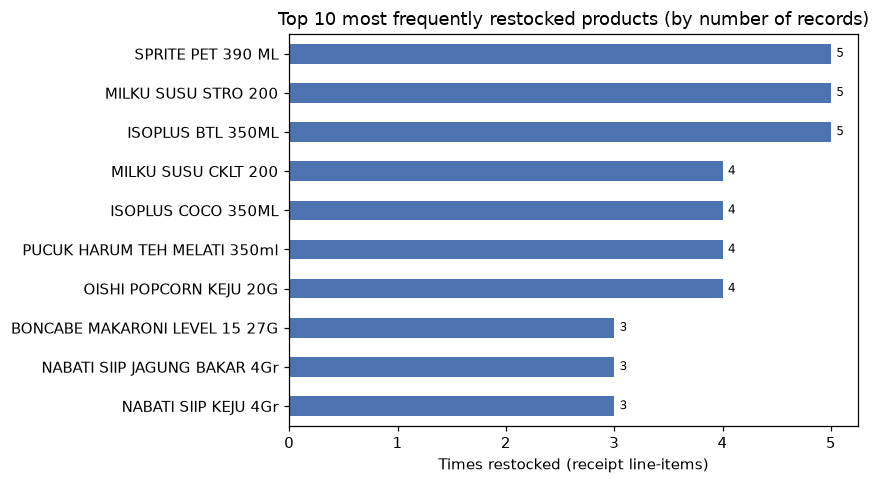

In [20]:
# 5.1 Most frequently restocked products (by record count).
fig, ax = plt.subplots(figsize=(8, 4.5))
freq.sort_values().plot(kind='barh', ax=ax, color='#4C72B0')
ax.set_title("Top 10 most frequently restocked products (by number of records)")
ax.set_xlabel("Times restocked (receipt line-items)")
ax.set_ylabel("")
for i, v in enumerate(freq.sort_values().values):
    ax.text(v + 0.05, i, str(int(v)), va='center', fontsize=8)
plt.tight_layout(); plt.show()

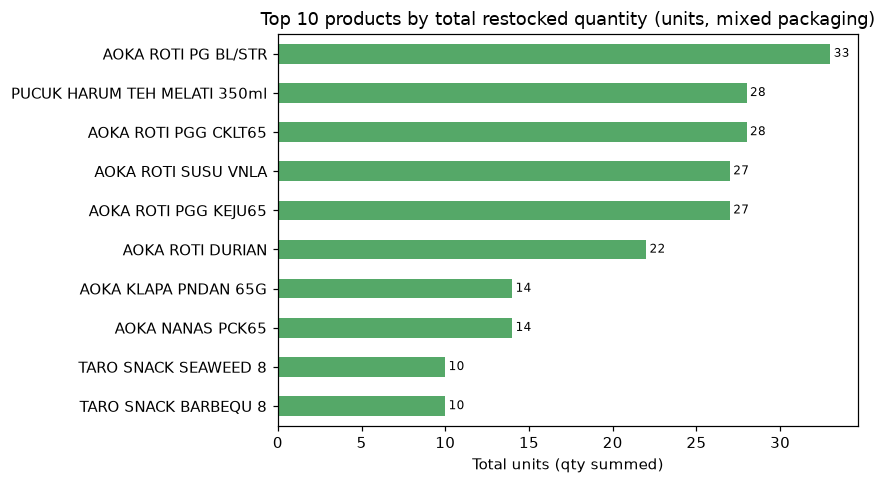

In [21]:
# 5.2 Products with the highest total restock quantity.
fig, ax = plt.subplots(figsize=(8, 4.5))
top_qty.sort_values().plot(kind='barh', ax=ax, color='#55A868')
ax.set_title("Top 10 products by total restocked quantity (units, mixed packaging)")
ax.set_xlabel("Total units (qty summed)")
ax.set_ylabel("")
for i, v in enumerate(top_qty.sort_values().values):
    ax.text(v + 0.2, i, str(int(v)), va='center', fontsize=8)
plt.tight_layout(); plt.show()

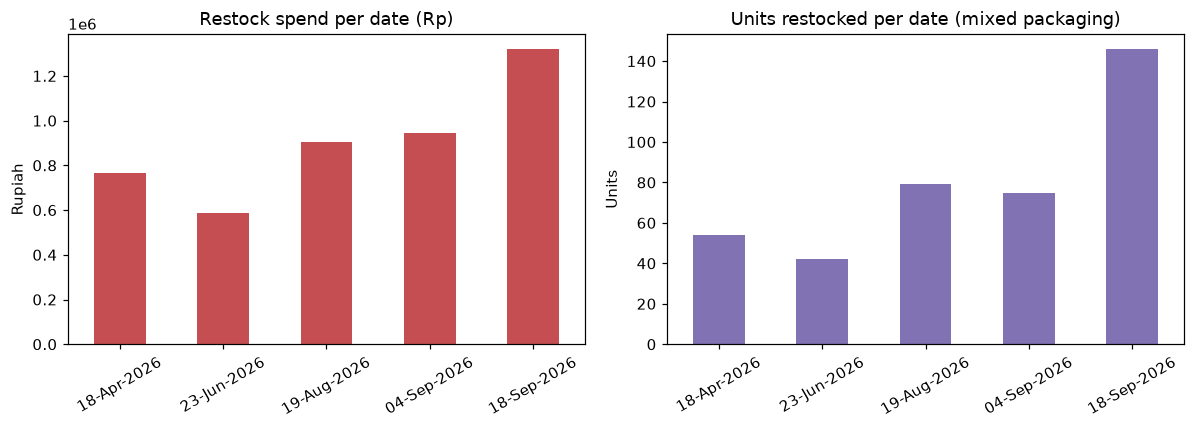

In [22]:
# 5.3 Restock spend and units per date (two panels - different metrics, not mixed).
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
bd = by_date.copy()
bd.index = bd.index.strftime('%d-%b-%Y')
bd['spend_rp'].plot(kind='bar', ax=ax[0], color='#C44E52')
ax[0].set_title("Restock spend per date (Rp)"); ax[0].set_ylabel("Rupiah"); ax[0].set_xlabel("")
ax[0].tick_params(axis='x', rotation=30)
bd['units'].plot(kind='bar', ax=ax[1], color='#8172B3')
ax[1].set_title("Units restocked per date (mixed packaging)"); ax[1].set_ylabel("Units"); ax[1].set_xlabel("")
ax[1].tick_params(axis='x', rotation=30)
plt.tight_layout(); plt.show()

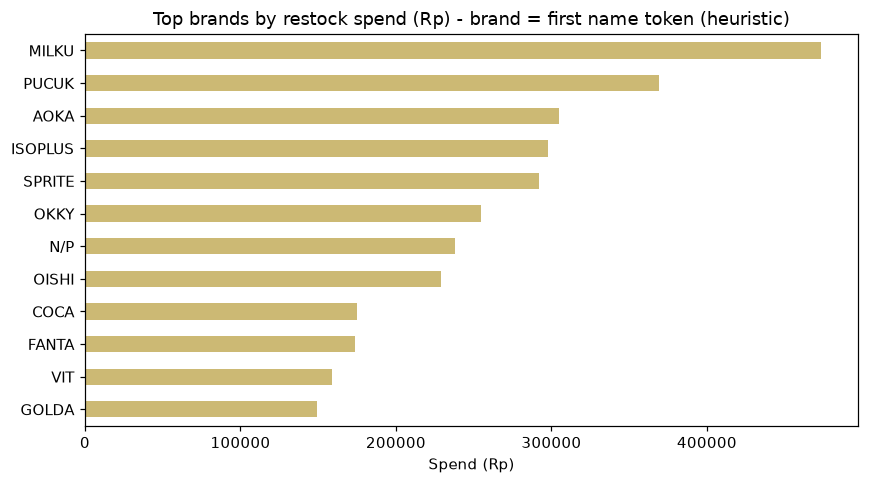

In [23]:
# 5.4 Brand-level spend (top brands). Heuristic brand = first name token.
fig, ax = plt.subplots(figsize=(8, 4.5))
brand['spend_rp'].sort_values().plot(kind='barh', ax=ax, color='#CCB974')
ax.set_title("Top brands by restock spend (Rp) - brand = first name token (heuristic)")
ax.set_xlabel("Spend (Rp)"); ax.set_ylabel("")
plt.tight_layout(); plt.show()

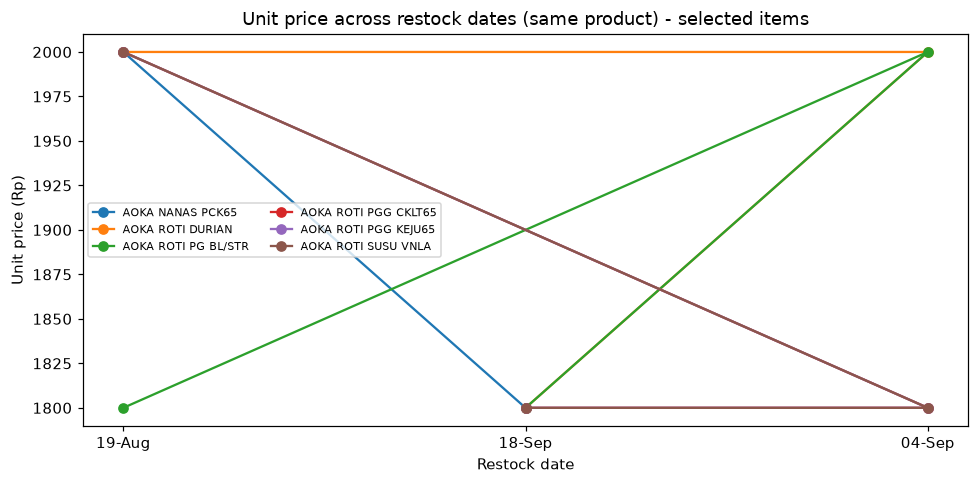

In [24]:
# 5.5 Price of a few products across restock dates (where it changed).
to_plot = changed.head(6)
fig, ax = plt.subplots(figsize=(9, 4.5))
for name, row in to_plot.iterrows():
    s = row.dropna()
    ax.plot(s.index.strftime('%d-%b'), s.values, marker='o', label=name[:22])
ax.set_title("Unit price across restock dates (same product) - selected items")
ax.set_ylabel("Unit price (Rp)"); ax.set_xlabel("Restock date")
ax.legend(fontsize=7, ncol=2)
plt.tight_layout(); plt.show()

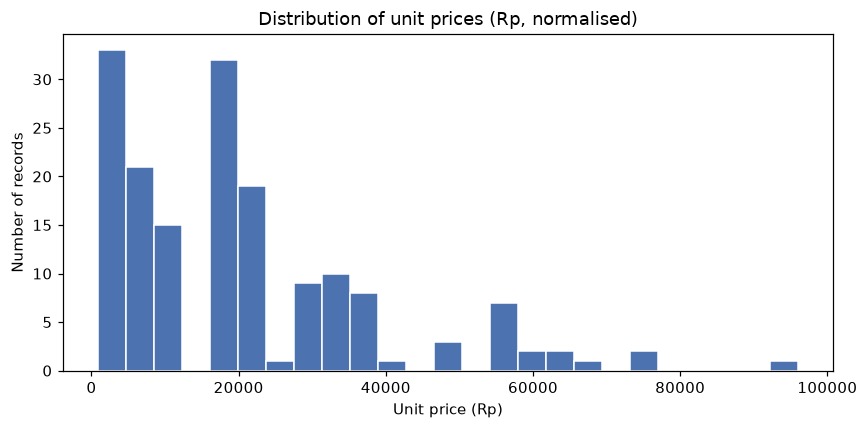

In [25]:
# 5.6 Distribution of unit prices (rupiah) - shows the product price spread.
fig, ax = plt.subplots(figsize=(8, 4))
df['unit_price_rp'].dropna().plot(kind='hist', bins=25, ax=ax, color='#4C72B0', edgecolor='white')
ax.set_title("Distribution of unit prices (Rp, normalised)")
ax.set_xlabel("Unit price (Rp)"); ax.set_ylabel("Number of records")
plt.tight_layout(); plt.show()

## 6. Key Findings and Recommendations

### 6.1 Dataset summary (facts)
The cleaned restock table holds **167 line-items** across **5 shopping trips**
(18-Apr, 23-Jun, 19-Aug, 04-Sep, 18-Sep 2026), covering **90 distinct products** after
brand-name standardisation and removal of *jastip* items. The three headline metrics are
reported separately in section 4.1.

### 6.2 Key findings (observed, not assumed)
*(All figures are produced by the cells above; re-run to confirm.)*

1. **Buying is dominated by a few bakery SKUs by volume.** **AOKA** bread variants take the
   top total-quantity spots (e.g. *AOKA ROTI PG BL/STR* ~33 units), and AOKA leads brand
   units by a wide margin. This is a **purchasing-volume** fact only - it does **not** mean
   these sell fastest; the data has no sales records.
2. **Frequency vs volume differ.** The most *frequently* restocked items (appearing on the
   most receipts - e.g. SPRITE, MILKU, ISOPLUS drinks) are **not** the same as the
   highest-*quantity* items (AOKA breads). Frequency suggests steady, small top-ups;
   high quantity suggests occasional bulk buys.
3. **Prices for the same product vary across trips.** ~20 products appear on more than one
   date with a changing unit price (e.g. COCA COLA, MILKU, NABATI lines), i.e. Indogrosir
   pricing/promotions shift between trips.
4. **Spend is uneven across trips.** The 18-Sep trip is the largest by both units and spend;
   the 23-Jun trip is the smallest.

### 6.3 Practical recommendations for restocking / inventory
- **Track the high-frequency drinks** (SPRITE, MILKU, ISOPLUS) as regular staples - they
  are bought almost every trip, so they likely need reliable reorder points.
- **Plan bulk bakery buys** (AOKA) deliberately - they drive unit volume and shelf space;
  align trip timing with their short shelf life.
- **Record a purchase price per trip** and watch the ~20 price-varying products; buying
  them on lower-price trips could cut cost.
- **Fix data capture at source** (see 6.4) so future analyses - especially any that join
  restock cost to sales - are trustworthy.

### 6.4 Remaining data-quality issues (report only - not auto-fixed)
1. **Mixed date formats / string dates** - `dd-mm-yyyy` vs `dd-mm-yy`, stored as text.
   Parsed here for analysis; the admin should standardise to real dates at source.
2. **Mixed monetary scale** - the 18-Sep sheet stores prices as decimals (thousands).
   Analysis uses a derived `unit_price_rp`; raw values are preserved. A single consistent
   scale at entry would remove this risk.
3. **One transcription inconsistency** - *ISOPLUS COCO 350ML* shows `unit_price = 2500` yet
   `total_after = 30000` on one receipt (section 3.6). Needs manual confirmation.
4. **`qty` mixes packaging units** (pieces vs cartons via `isi`). "Total units" is therefore
   indicative, not a like-for-like piece count.
5. **Sparse optional columns** - `discount`, `profit`, `sisa`, `rusak`, `transaction_no`
   are often blank; `transaction_no` is missing for the 18-Sep sheet and shared across two
   sheets. These limit per-transaction and margin analysis.
6. **Brand = first name token is a heuristic** - fine for AOKA/NABATI/OISHI, unreliable for
   coded names (e.g. *N/P*, *S/N*, *BC*). Treat brand rollups as approximate.

### 6.5 Limitations
- This is **restock/purchasing data only**: no sales, consumption, wastage-over-time, or
  profit realised. Statements about popularity or profitability are out of scope.
- Only **5 shopping trips** are available, so date-based trends are directional, not
  statistically strong.

### 6.6 Conclusion
After cleaning and brand standardisation, the dataset is **analysis-ready for
purchasing-pattern questions**: it reliably answers *what was bought, how often, in what
quantity, and at what cost per trip*. The main watch-items are the mixed date/price formats
and a couple of transcription oddities, all documented above and preserved rather than
silently changed. Used within those limits, the findings give Kaftet a clear, evidence-based
basis for planning staple reorders, bulk bakery buys, and price-aware purchasing - while
noting that confirming what actually *sells* would require separate sales data.